**Aim:** Identify cell types – cluster annotation 

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)

In [1]:
import scez
import scanpy as sc
import anndata as ad

import matplotlib.pyplot as plt
from upsetplot import from_contents, UpSet

from utils import *

scanpy==1.9.6 anndata==0.10.7 umap==0.5.5 numpy==1.26.4 scipy==1.13.0 pandas==2.1.4 scikit-learn==1.2.2 statsmodels==0.14.2 igraph==0.11.5 pynndescent==0.5.12


## Load data 
~`adata` -> `scvi` denoised and then clustered~

In [2]:
# results_file = 'preprocessing/adata-denoised-clustered-v3.h5ad.gz'
results_file = 'preprocessing/adata-cleaned.h5ad.gz'

adata = sc.read_h5ad(results_file)

In [3]:
# Randomly order cells by making a random index and subsetting AnnData based on it
# Set a random seed to ensure that the cell ordering will be reproducible
np.random.seed(0)
random_indices = np.random.permutation(list(range(adata.shape[0])))

In [4]:
# del adata.raw, adata.var, adata.uns, adata.varm, adata.obsp

# for col in adata.obs.columns[adata.obs.columns.str.startswith('_')]: 
#     del adata.obs[col]

In [5]:
# for col in adata.obs.filter(like='label').columns:
#     del adata.obs[col]

In [6]:
# adata.var_names_make_unique()

In [7]:
adata

AnnData object with n_obs × n_vars = 24686 × 12359
    obs: 'batch', 'cond', 'group', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden_cleaned'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'ambient_profile_Gene Expression', 'group_colors', 'hvg', 'leiden', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'log1p_norm', 'raw_counts', 'scaled', 'scar_denoised_counts'
    obsp: 'connectivities', 'distances'

___

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:371: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:381: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  ax.scatter(


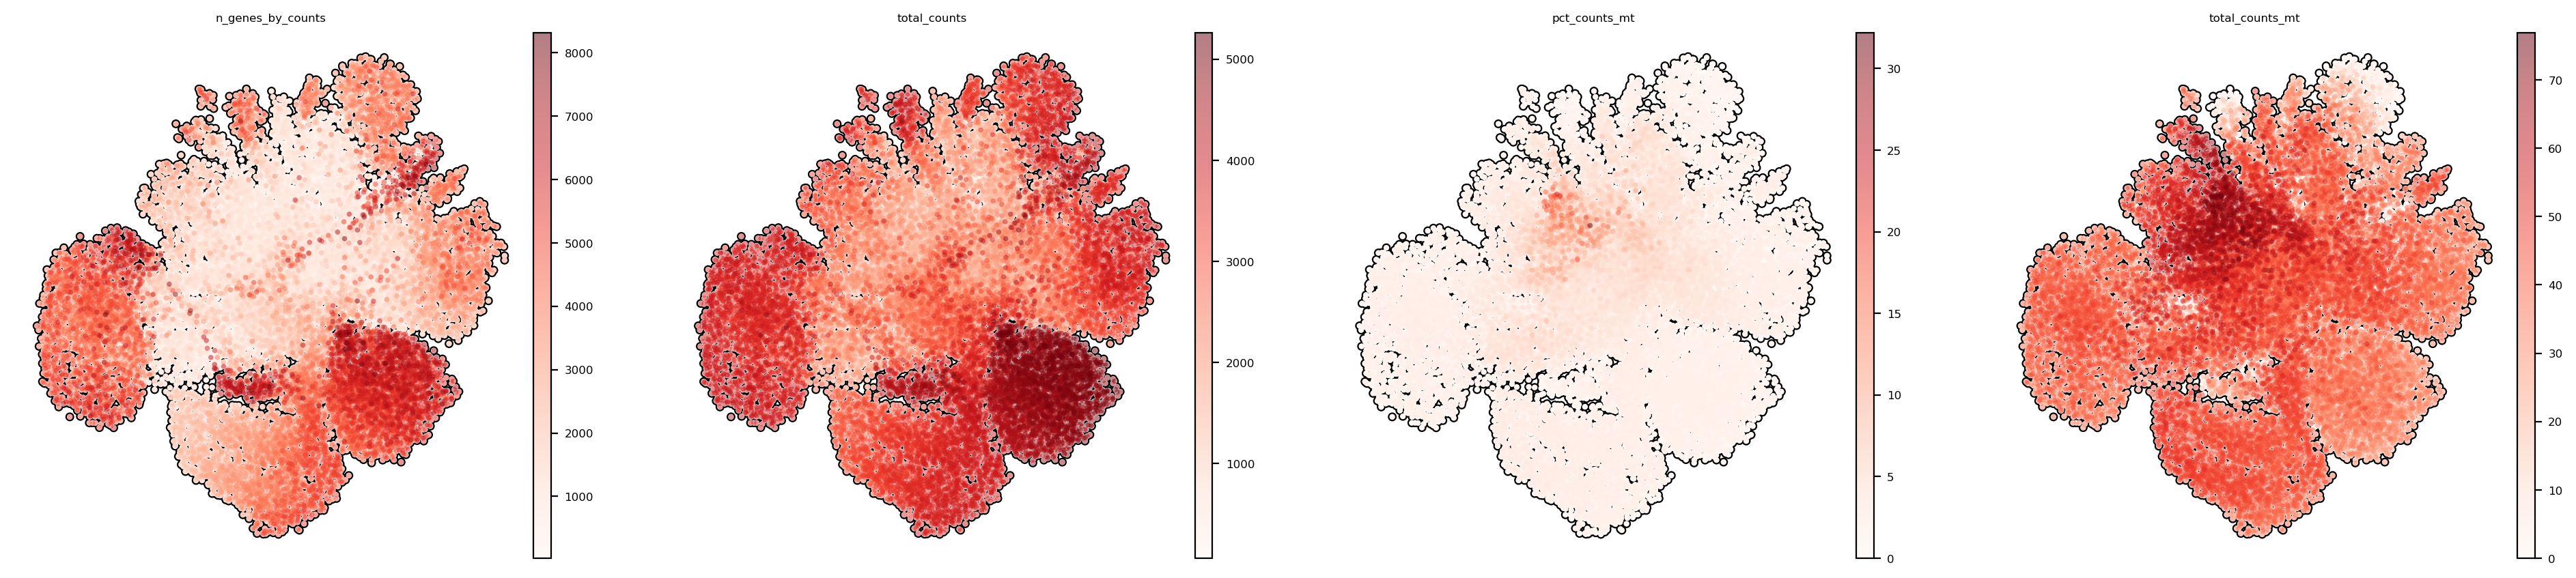

In [8]:
sc.pl.umap(adata[random_indices], color=['n_genes_by_counts', 
                        'total_counts', 
                        'pct_counts_mt',
                        'total_counts_mt'],
               color_map="Reds",
    frameon=False,alpha=0.5,size=30,
    # legend_loc='on data',
    add_outline=0.1
)

## marker genes for neuronal/non-neuronal cells

In [9]:
cell_types = {
    "non-neuron":[
        "Endothelial",
        "Oligodentrocyte",
        "Microglia",
        "astrocytes",
    ],
    "neuron":[
        "GABAergic",
        "glutamatergic",
        "D1 MSN",
        "D2 MSN",
        "D1H",
        "ICj"
    ]
}

In [10]:
saba_s_genes = [
    "Tac1",
    "Pcp4",
    "Ly6h",
    "Syt5",
    "Caly",
    "Snhg11",
    "Ctxn1",
    "Rtn1",
    "Bex2",
    "Meg3"
]

In [30]:
marker_genes = {
    "Endothelial": ["Cldn5","Flt1","Id1","Ptprb"],
    "Smooth Muscle":['Cald1',"Rgs5"],
    "Oligodentrocyte":["Mog",'Opalin'], #, "Olig1"],
    "Microglia":['C1qb','C1qa'], #"Cx3cr1"],
    "astrocytes":[
        # 'Aldoc',
        'Slc1a2',
        # 'Slc1a3','Gja1'
        
    
    ], # "Aqp4"],
    "Neuron":[
        'Snap25','Sox11',
        # "Gt(ROSA)26Sor"
    ],
    
    # "GABAergic":["Gad1"],
    # "glutamatergic":[
    #     "Grin3a",
    #     "Lrrtm2",
    #     "Slc1a1",
    #     "Slc1a2",
    #     "Gria1",
    #     # "Gria2",
    #     # "Grin1",
    #     # "Slc6a13",
    #     # "Slc7a11",
    #     # "Slc17a7",
    #     # "Slc17a6",
    # ],
    "D1/2 MSN":[
        "Arpp21",
        # "Ppp3ca",
        'Tac1',
        # "Pdyn",
        "Sfxn1",
        "Pcdh8",
        "Adarb2",
        # "Tshz1",
        "Ptpn5",
        "Snca",
    ],
    
    "OPC":[
        "Pdgfra",
    ],
    
    # "D1H":[
        # "Nxph4",
        # "Tac2"
    # ],
    # "ICj":[
        # "Crtac1",
        # "Rreb1"],
    # "patch marker":["Sema5b"],
    # "ventral striatum marker":["Crym"],
    # "medial Shell":[
    #     "Stard5",
    #     "Stra6"]
#     "Interneurons":[
#         'Resp18', # as initial marker
#         # "Chat", 
#         "Pvalb", 
#         # "Trh", 
#         "Calb2", 
#         # "Pthlh", 
#         "Afap1", "Hhip", #"Crhbp" # - sub clustering: 
#         # - some are overlapping and labeled by combination of multiple or as high or low e.g. Sst+/Hhip+, Sst+/Hhip−
#     ]
}    

In [31]:
not_neuron_genes = dict([(k,v) for k,v in marker_genes.items() if k in cell_types['non-neuron']])

In [32]:
neuron_genes = dict([(k,v) for k,v in marker_genes.items() if k in cell_types['neuron']])

## Dot plots

categories: 0, 1, 2, etc.
var_group_labels: Endothelial, Smooth Muscle, Oligodentrocyte, etc.


/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


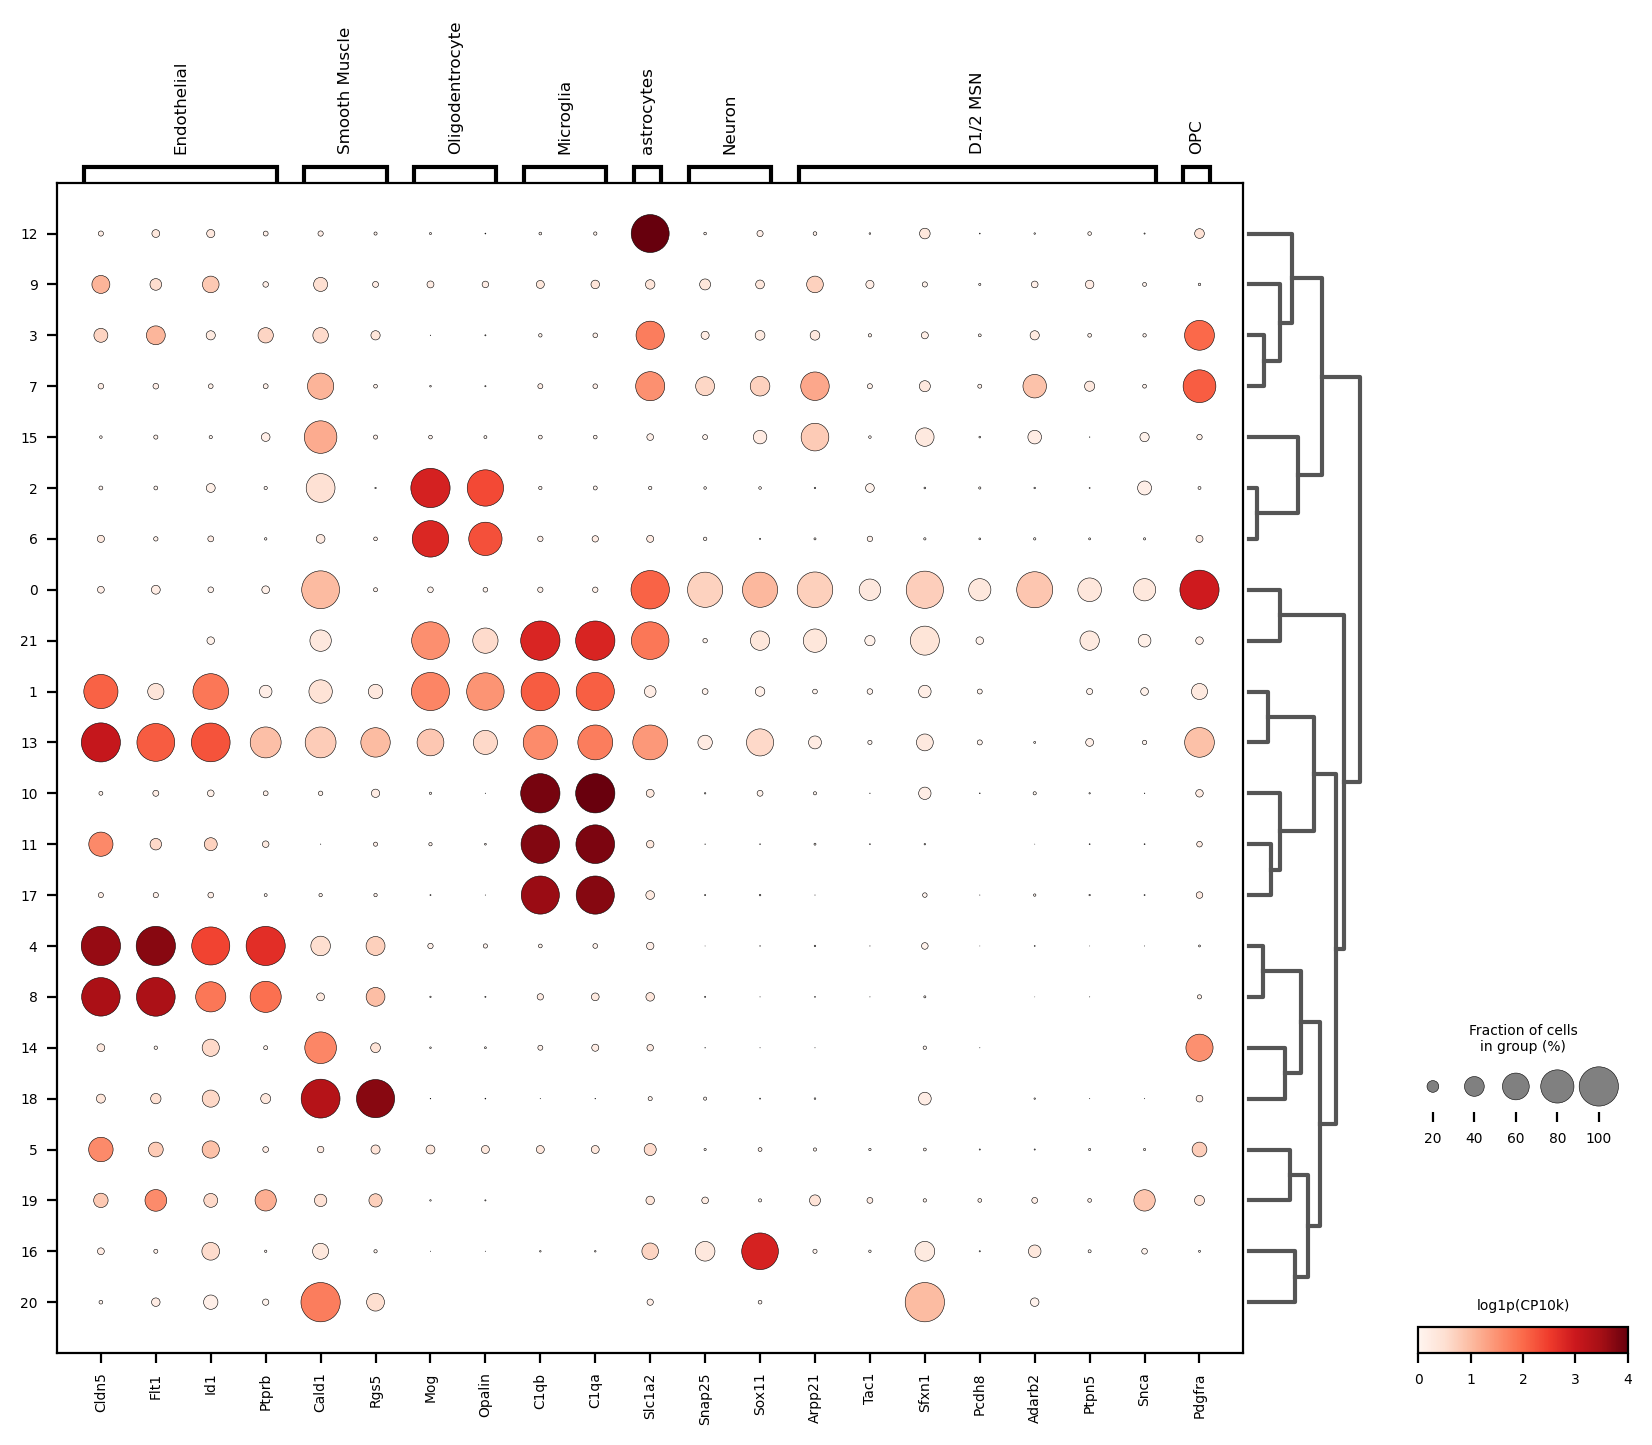

In [33]:
ax = sc.pl.dotplot(
    adata,
    # saba_s_genes,
    marker_genes, 
    groupby=['leiden_cleaned'], #,'leiden_scVI'
    swap_axes=False, 
    dendrogram=True,
    colorbar_title='log1p(CP10k)', 
    layer='log1p_norm', 
    vmin=0, vmax=4, 
    cmap='Reds'

    # layer='scaled', 
    # vmin=-1, vmax=1, 
    # cmap='RdBu_r',
    # colorbar_title='mean z-score', 

    # save = 'non_neuron'
)

# !mv -v figures/dotplot_non_neuron.pdf celltyping/non_neuron_dotplot.pdf

____
#### Annotate clusters:

In [27]:
leiden_list = []

for l in adata.obs.leiden_cleaned:
    if int(l) in [10,11,17]: leiden_list.append('Microglia')
    elif int(l) in [12]: leiden_list.append('Astrocytes')
    elif int(l) in [1,4,8,13]: leiden_list.append('Endothelial')
    elif int(l) in [18]: leiden_list.append('Smooth Muscle')
    # elif int(l) in [14]: leiden_list.append('OPC')
    elif int(l) in [2,6]: leiden_list.append('Oligodendrocytes')
    # elif int(l) in [0,1,7,9,14,20]: leiden_list.append('D1/2 Neuron')
    elif int(l) in [
        0,3,5,7,9,
        15,16,19,20,21
        # 14,
    #     # 1,9,
    #     # 0,
    #     3,5,7,16,14,15,16,18,19,20,21
    ]:leiden_list.append('Neuron')
    else: leiden_list.append(l)

adata.obs['label'] = pd.Categorical(leiden_list)

In [28]:
sc.tl.dendrogram(adata,['label']) 
sc.tl.dendrogram(adata,['label','leiden_cleaned']) 

categories: 14, Astrocytes, Endothelial, etc.
var_group_labels: Endothelial, Smooth Muscle, Oligodentrocyte, etc.


/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


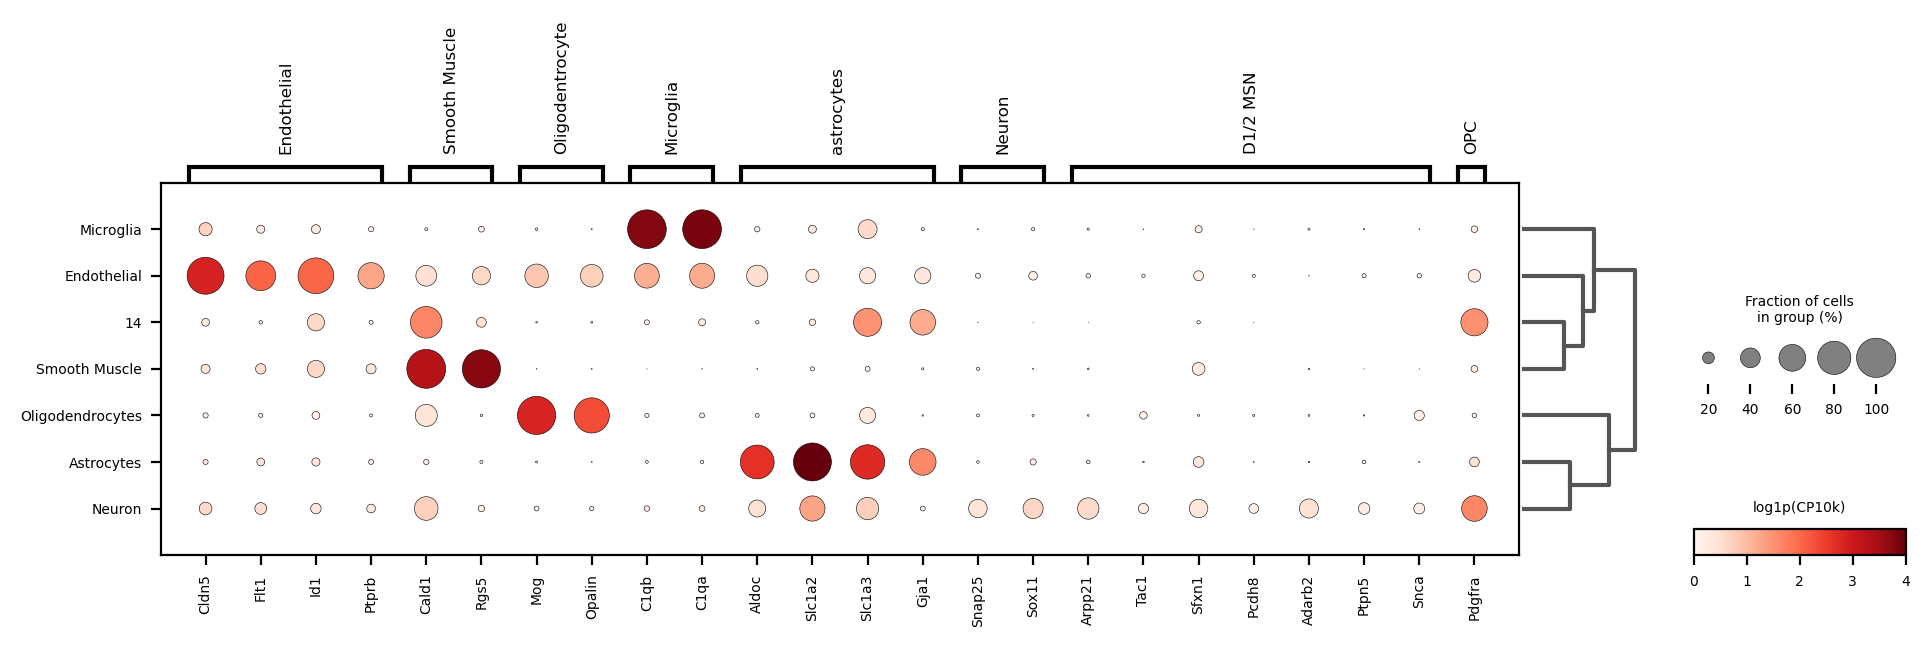

In [29]:
ax = sc.pl.dotplot(
    adata,
    marker_genes, 
    # not_neuron_genes, 
    groupby=['label'], 
    swap_axes=False, dendrogram=True,

    colorbar_title='log1p(CP10k)', 
    layer='log1p_norm', 
    vmin=0, vmax=4, 
    cmap='Reds'

    # layer='scaled', 
    # vmin=-1, vmax=1, 
    # cmap='RdBu_r',
    # colorbar_title='mean z-score', 

    # save = 'Snap25_neg'
)

# !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_utils.py:431: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:371: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:381: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anacon

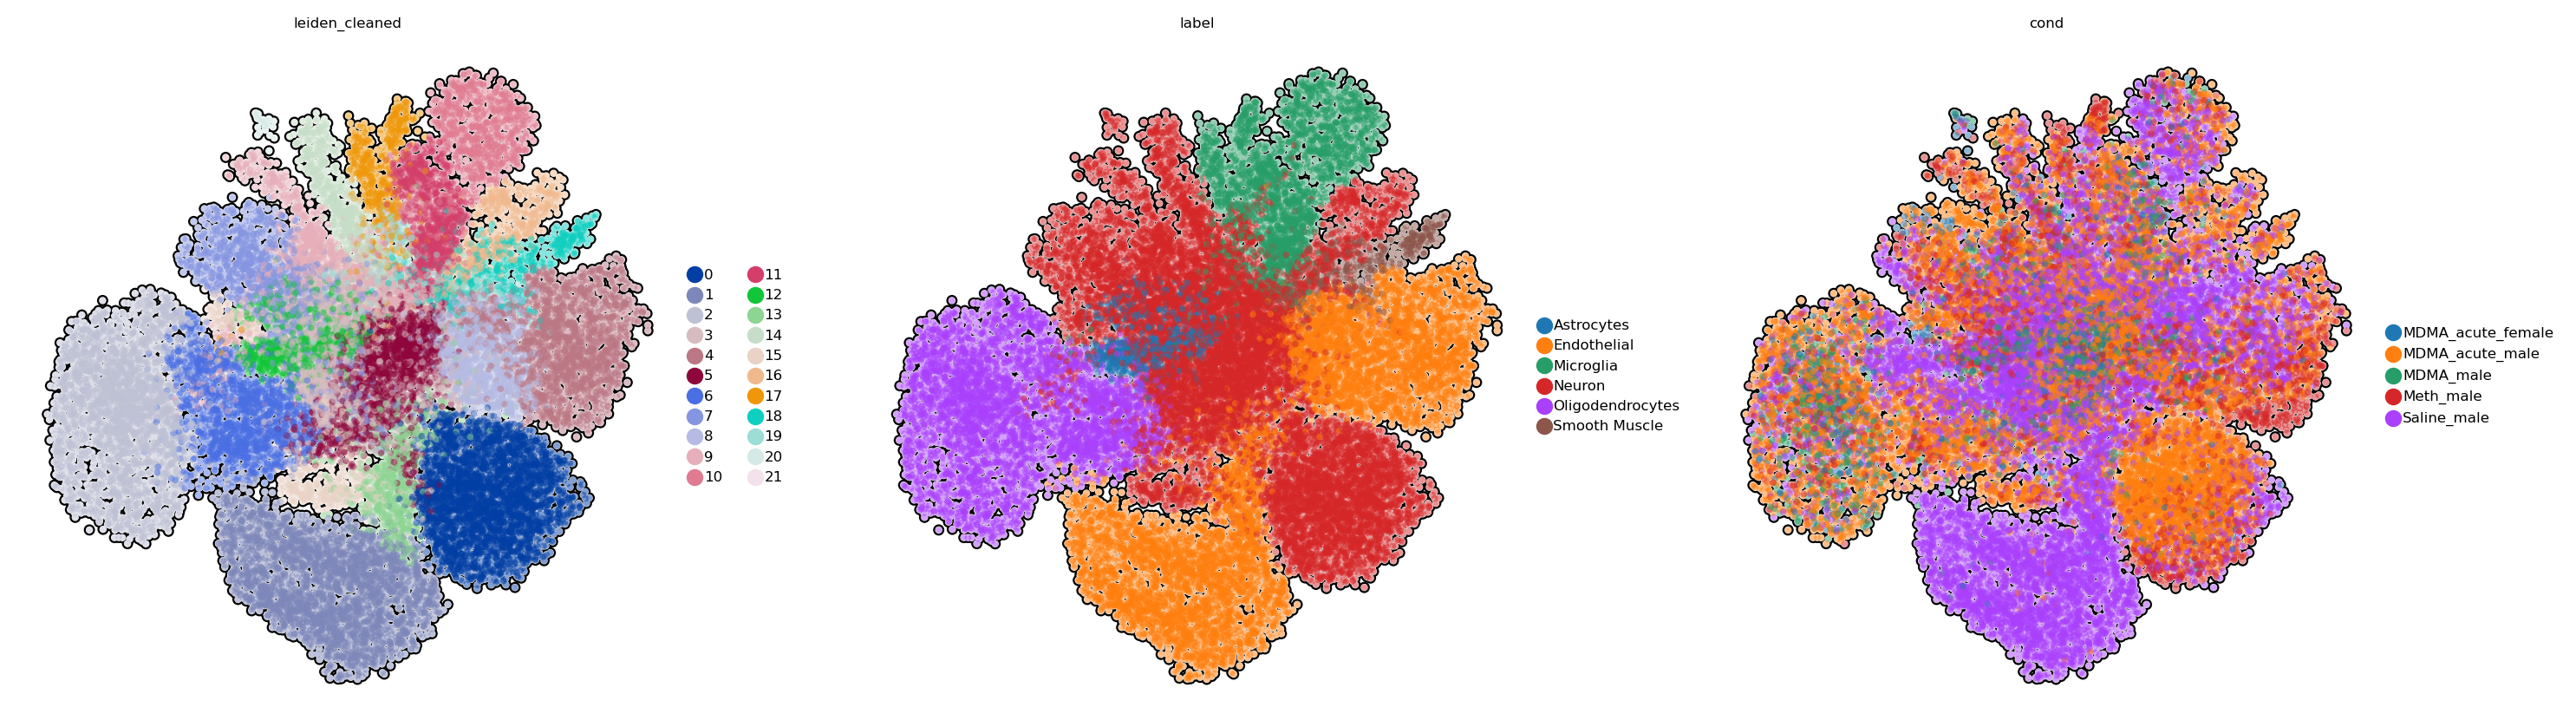

In [347]:
sc.pl.umap(
    adata[random_indices],
    # adata[adata.obs.leiden_cleaned.isin([str(i) for i in[
    #     0,1,2,3,4,#5,6,7,11,12,14,15,17,19,20,21,22
    # ]])],
    layer='log1p_norm', 
    color=['leiden_cleaned','label','cond',
           # 'Mog','Sorl1','Tshz1','Cldn5','C1qa','C1qb'
          ],
    color_map="Reds",
    frameon=False,alpha=0.5,size=30,
    # legend_loc='on data',
    add_outline=0.1
)

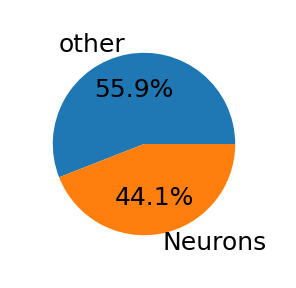

In [348]:
d = pd.DataFrame(adata.obs['label'].str.contains('Neuron')).groupby('label').size()

fig = plt.figure(figsize =(1, 1),dpi=150)
plt.pie(d.values,labels=['other','Neurons'],autopct='%1.1f%%')
# show plot
plt.show()

___
<!-- ### Label tdT+/-
Divide cells into `Gt(ROSA)26Sor+` and `'Gt(ROSA)26Sor-` populations -->

In [349]:
# tdT_gene = "Gt(ROSA)26Sor"

In [351]:
# ax = scez.utils.add_marker_feature(adata,marker=tdT_gene,marker_name='TdT label',clusters_name='leiden_scVI')

# # plt.savefig('celltyping/percent_in_clust_denoised_TdT.pdf')
# # # show plot
# plt.show()

## Split dataset

In [352]:
adata_neuron = adata[adata.obs.label == 'Neuron'].copy()

In [353]:
adata_non_neuron = adata[adata.obs.label != 'Neuron'].copy()

# Neurons

In [370]:
# Randomly order cells by making a random index and subsetting AnnData based on it
# Set a random seed to ensure that the cell ordering will be reproducible
np.random.seed(0)
random_indices_neuron = np.random.permutation(list(range(adata_neuron.shape[0])))

#### Scale

In [371]:
adata_neuron.layers['scaled'] = sc.pp.scale(adata_neuron, copy=True).X

In [372]:
# The result of the previous highly-variable-genes detection is stored as 
# an annotation in .var.highly_variable and auto-detected by PCA and hence, 
# sc.pp.neighbors and subsequent manifold/graph tools. 
# In that case, the step actually do the filtering below is unnecessary, too.

sc.pp.highly_variable_genes(
    adata_neuron, min_mean=0.0125, max_mean=3, min_disp=0.5,
)

#### sub-clustering

In [373]:
adata_neuron

AnnData object with n_obs × n_vars = 10875 × 12359
    obs: 'batch', 'cond', 'group', 'n_counts', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden_cleaned', 'label', 'leiden_neuron'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'ambient_profile_Gene Expression', 'group_colors', 'hvg', 'leiden', 'neighbors', 'pca', 'umap', 'dendrogram_leiden_cleaned', 'dendrogram_label', 'dendrogram_label_leiden_cleaned', 'leiden_cleaned_colors', 'leiden_neuron_colors', 'cond_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'log1p_norm', 'raw_counts', 'scaled', 'scar_denoised_counts'
    obsp: 'connectivities', 'distances'

In [377]:
sc.pp.neighbors(adata_neuron)
sc.tl.umap(adata_neuron, min_dist=0.3)
sc.tl.leiden(adata_neuron, key_added="leiden_neuron", resolution=0.1)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


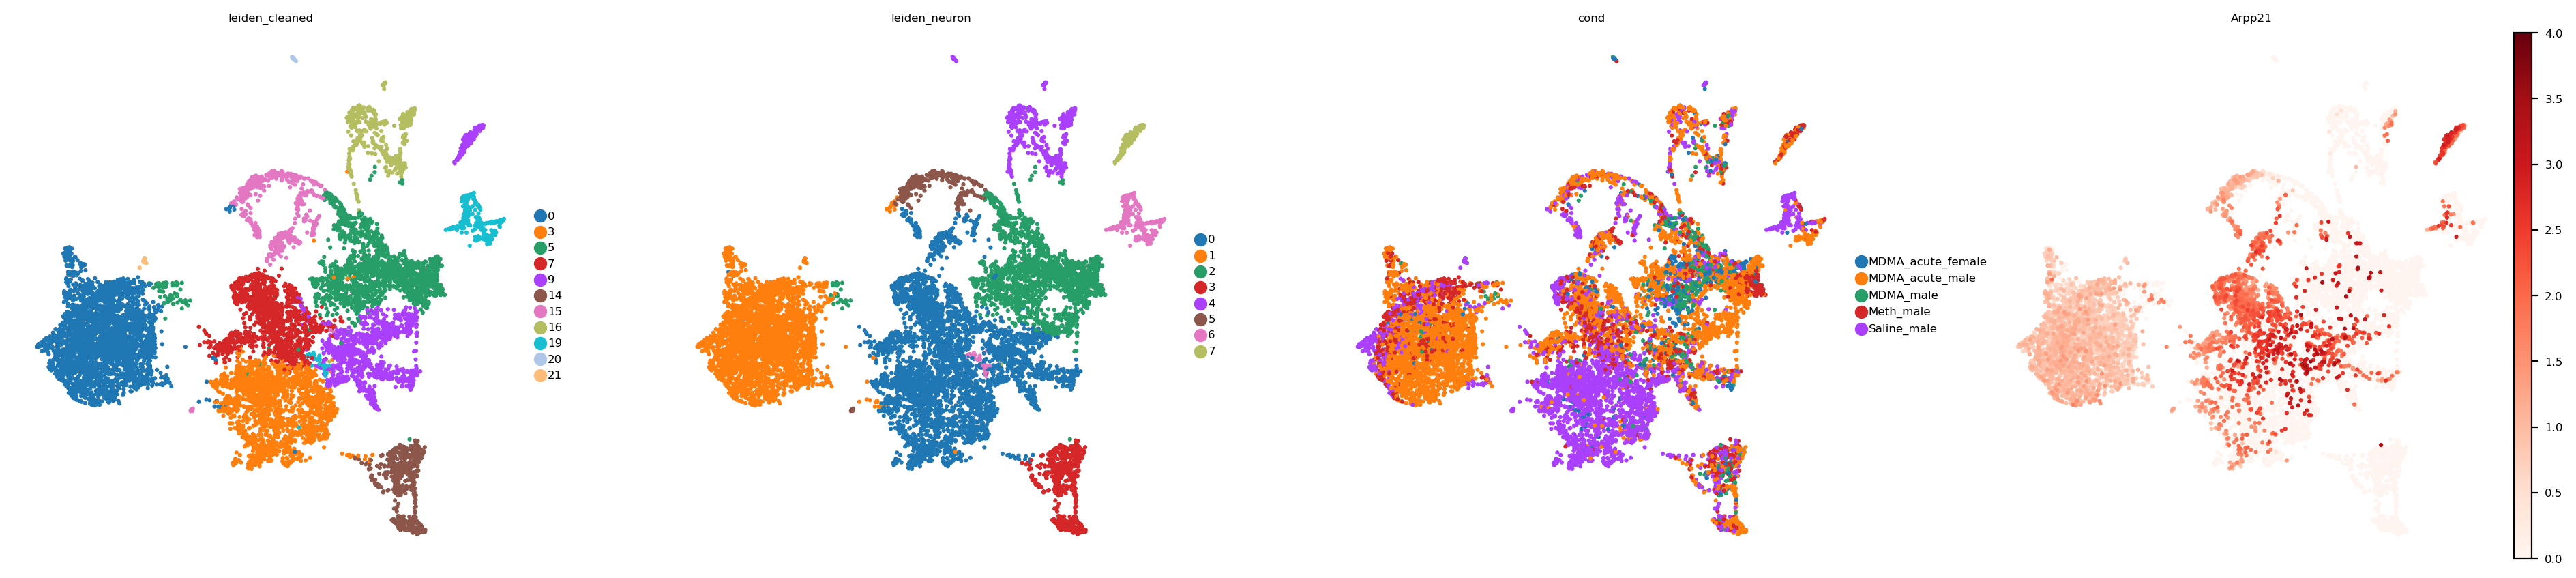

In [384]:
sc.pl.umap(
    adata_neuron[random_indices_neuron], 
    # color='leiden_neuron'
    # layer='log1p_norm',
    color=['leiden_cleaned','leiden_neuron','cond'] + marker_genes['D1/2 MSN'][:1],
    frameon=False,
    # alpha=0.5,
    size=20,

    layer='log1p_norm', 
    vmin=0, vmax=4, 
    cmap='Reds',

    # legend_loc='on data',
    # add_outline=0.0001

)

#### save small data for browser view
https://www.kanaverse.org/kana/

In [409]:
adata_neuron_small = adata_neuron.copy()

# adata_neuron_small = adata_neuron_small[:,adata_neuron_small.var.highly_variable].copy()

adata_neuron_small.var = adata_neuron_small.var.reset_index().rename(
    columns={'index':'gene_names'}).set_index('gene_ids')

In [410]:
del adata_neuron_small.layers

del adata_neuron_small.uns['ambient_profile_Gene Expression']
del adata_neuron_small.uns['group_colors']

for col in ["n_counts","n_genes_by_counts","total_counts","total_counts_mt","pct_counts_mt"]:
    del adata_neuron_small.obs[col]

for col in adata_neuron_small.var.columns:
    if col not in ["gene_names","total_counts",'highly_variable']:
        del adata_neuron_small.var[col]

In [411]:
del adata_neuron_small.uns['dendrogram_label_leiden_cleaned']
del adata_neuron_small.uns['dendrogram_leiden_cleaned']
del adata_neuron_small.uns['dendrogram_label']

In [412]:
adata_neuron_small

AnnData object with n_obs × n_vars = 10875 × 12359
    obs: 'batch', 'cond', 'group', 'leiden_cleaned', 'label', 'leiden_neuron'
    var: 'gene_names', 'total_counts', 'highly_variable'
    uns: 'hvg', 'leiden', 'neighbors', 'pca', 'umap', 'leiden_cleaned_colors', 'leiden_neuron_colors', 'cond_colors', 'rank_genes_groups'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [413]:
results_file = 'celltyping/adata_neuron.small.h5ad'

adata_neuron_small.write(results_file)

In [414]:
!ls -s --block-size=M celltyping/adata_neuron*

1044M celltyping/adata_neuron.small.h5ad


#### save top genes per cluster

In [401]:
sc.tl.rank_genes_groups(
    adata_neuron, 'leiden_neuron', method='wilcoxon'
)

In [402]:
neuron_ranked_clusters_full = scez.utils.rank_genes_to_df(
    adata_neuron,
    n = 200
)

In [407]:
neuron_ranked_clusters_full.add_prefix('neuron_').to_csv('celltyping/ranked_neuron_clusters_full.csv')

In [ ]:
sc.tl.dendrogram(adata_neuron,'leiden_neuron') 

In [ ]:
ax = sc.pl.dotplot(
    adata_neuron,
    neuron_genes, 
    # marker_genes, 
    groupby=['leiden_neuron'], #,'leiden_scVI'
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    layer='scaled', 
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'non_neuron'
)

# !mv -v figures/dotplot_non_neuron.pdf celltyping/non_neuron_dotplot.pdf

In [ ]:
# leiden_list = []
# for l in adata_neuron.obs.leiden_non_neuron:
#     if int(l) in [4]: leiden_list.append('Microglia')
#     elif int(l) in [3]: leiden_list.append('Astrocytes')
#     elif int(l) in [1]: leiden_list.append('Endothelial')
#     elif int(l) in [0]: leiden_list.append('Oligodendrocytes')
#     else: leiden_list.append(l)

# adata_neuron.obs['label'] = pd.Categorical(leiden_list)

In [ ]:
# sc.tl.dendrogram(adata_neuron,'label') 

In [ ]:
# ax = sc.pl.dotplot(
#     adata_neuron,
#     not_neuron_genes, 
#     groupby=['label','leiden_scVI'], 
#     swap_axes=False, dendrogram=True,
#     colorbar_title='mean z-score', 
#     layer='scaled', 
#     vmin=-1, vmax=1, cmap='RdBu_r',
#     # save = 'Snap25_neg'
# )

# # !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

In [ ]:
# sc.pl.violin(adata_neuron, ['n_genes_by_counts', 
#                         'total_counts', 
#                         'pct_counts_mt',
#                         'total_counts_mt'],
#              jitter=0.05, multi_panel=True)

In [ ]:
sc.pl.umap(
    adata_neuron,
    color=[
        'leiden_scVI',
        'leiden_neuron',
        'label',
        # 'mean_counts',
        "Foxp1",
        "Kcnc1", "Acan", "Pvalb", "Junb",
        "Snap25",'Sox11',
        "Mog","Ptprb",
        'group',
    ],
    # vmax=2,
    # vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=30,
    # legend_loc='on data',
    add_outline=0.1
)

### Save to file

Here, we need to think more about how to find subclusters!

In [ ]:
results_file = 'celltyping/adata_neuron-clustered-v3.h5ad.gz'

adata_neuron.write_h5ad(results_file)

# Non-Neurons

In [ ]:
adata_non_neuron

#### Scale

In [ ]:
adata_non_neuron.layers['scaled'] = sc.pp.scale(adata_non_neuron, copy=True).X

In [ ]:
# The result of the previous highly-variable-genes detection is stored as 
# an annotation in .var.highly_variable and auto-detected by PCA and hence, 
# sc.pp.neighbors and subsequent manifold/graph tools. 
# In that case, the step actually do the filtering below is unnecessary, too.

sc.pp.highly_variable_genes(
    adata_non_neuron, min_mean=0.0125, max_mean=3, min_disp=0.5,
)

In [ ]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata_non_neuron, use_rep="X_scVI")
sc.tl.umap(adata_non_neuron, min_dist=0.3)
# neighbors were already computed using scVI
sc.tl.leiden(adata_non_neuron, key_added="leiden_non_neuron", resolution=0.1)

In [ ]:
sc.tl.dendrogram(adata_non_neuron,'leiden_non_neuron') 

In [ ]:
sc.pl.umap(
    adata_non_neuron, 
    color=['leiden_non_neuron'] + 
    [gene for _,genes in not_neuron_genes.items() for gene in genes],
    vmax=1,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=20,
    layer='scaled',
)

In [ ]:
ax = sc.pl.dotplot(
    adata_non_neuron,
    not_neuron_genes, 
    groupby=['leiden_non_neuron'], #,'leiden_scVI'
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    layer='scaled', 
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'non_neuron'
)

# !mv -v figures/dotplot_non_neuron.pdf celltyping/non_neuron_dotplot.pdf

In [ ]:
leiden_list = []
for l in adata_non_neuron.obs.leiden_non_neuron:
    if int(l) in [4]: leiden_list.append('Microglia')
    elif int(l) in [3]: leiden_list.append('Astrocytes')
    elif int(l) in [1]: leiden_list.append('Endothelial')
    elif int(l) in [0]: leiden_list.append('Oligodendrocytes')
    else: leiden_list.append(l)

adata_non_neuron.obs['label'] = pd.Categorical(leiden_list)

In [ ]:
sc.tl.dendrogram(adata_non_neuron,'label') 

In [ ]:
ax = sc.pl.dotplot(
    adata_non_neuron,
    not_neuron_genes, 
    groupby=['label','leiden_scVI'], 
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    layer='scaled', 
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'Snap25_neg'
)

# !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

In [ ]:
sc.pl.umap(
    adata_non_neuron,
    color=[
        'leiden_scVI',
        'leiden_non_neuron',
        'label',
        # "Mog","Ptprb",
        # "Snap25",'Sox11',
        'group',
    ],
    vmax=2,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=30,
    # legend_loc='on data',
    add_outline=0.1
)

##### 
save :)

In [ ]:
results_file = 'celltyping/adata_non_neuron-clustered-labeled.h5ad.gz'

adata_non_neuron.write_h5ad(results_file)

# All data

In [ ]:
results_file = 'celltyping/adata_non_neuron-clustered-labeled.h5ad.gz'

adata_non_neuron = ad.read_h5ad(results_file)

In [ ]:
results_file = 'celltyping/adata_neuron-clustered.h5ad.gz'

adata_neuron = ad.read_h5ad(results_file)

In [ ]:
adata = ad.concat([adata_neuron, adata_non_neuron])

In [ ]:
adata.obs['final label'] = ''

adata.obs.loc[adata_neuron.obs_names,'final label'] = 'neuron'#list(adata_neuron.obs.leiden_neuron)
adata.obs.loc[adata_non_neuron.obs_names,'final label'] = list(adata_non_neuron.obs.label)

adata.obs['final label'] = pd.Categorical(list(adata.obs['final label']))

In [ ]:
adata

In [ ]:
adata.obs.loc[adata_neuron.obs_names,'leiden_neuron'] = list(adata_neuron.obs.leiden_neuron)
adata.obs['leiden_neuron'] = pd.Categorical(list(adata.obs['leiden_neuron']))

#### scale

In [ ]:
adata.layers['scaled'] = sc.pp.scale(adata, copy=True).X

In [ ]:
sc.pp.pca(adata,n_comps=30)

In [ ]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata, use_rep="X_scVI",n_neighbors=30)
sc.tl.umap(adata, min_dist=0.1)

In [ ]:
sc.pl.umap(
    adata,
    color=[
        # 'group',
        'leiden_scVI',
        # 'leiden_neuron',
        "TdT label",
        # 'Snap25 label',
        'final label',
        # "Sox11",'Snap25',
    ],
    vmax=.1,vmin=-.1,
    layer='scaled',
    color_map="Reds",
    frameon=False,
    # alpha=0.1,
    size=1,
    # legend_loc='on data',
    # add_outline=0.01,
    save = '_20230313'
)

!mv -v figures/umap_20230313.pdf celltyping/

### 

> - Groups and cell counts per group (would you please get me updated cell counts for each group?)

> - Amount that are tdT positive (less than expected – would you please generate a new UMAP highlighting tdT expression?)

In [ ]:
pd.DataFrame(
    adata.obs.groupby(['batch','final label']).size()
).rename(columns={0:'# of cells'}).to_excel('num_cell_per_group.xlsx')

### Save final `adata`

In [ ]:
adata_final = adata.copy()

In [ ]:
del adata_final.obsm, adata_final.raw, adata_final.var, adata_final.uns, adata_final.varm, adata_final.obsp

In [ ]:
for col in adata_final.obs.filter(like=' label').columns:
    del adata_final.obs[col]

In [ ]:
results_file = 'preprocessing/adata-annotated.h5ad.gz'

adata_final.write_h5ad(results_file)

In [ ]:
adata_final.to_df('counts').T.to_csv('preprocessing/adata-annotated-counts.csv.gz',compression='gzip')

In [ ]:
adata_final.obs.to_csv('preprocessing/adata-annotated-meta.csv.gz',compression='gzip')

In [ ]:
ls -lh preprocessing/adata-annotated*

# 

In [ ]:
!date